In [9]:
!pip install xgboost imbalanced-learn -q


In [10]:
# ===== Cell 2: Import all the libraries we need =====

# pandas: for loading and handling data (tables)
import pandas as pd

# numpy: for math and number operations
import numpy as np

# matplotlib & seaborn: for drawing charts and graphs
import matplotlib.pyplot as plt
import seaborn as sns

# train_test_split: splits data into training and testing parts
from sklearn.model_selection import train_test_split

# StandardScaler: puts all numbers on the same scale
from sklearn.preprocessing import StandardScaler

# The 3 machine learning models we will train and compare:
from sklearn.linear_model import LogisticRegression      # simple baseline model
from sklearn.ensemble import RandomForestClassifier      # strong tree-based model
from xgboost import XGBClassifier                         # powerful boosting model

# SMOTE: fixes imbalanced data by creating more fraud examples
from imblearn.over_sampling import SMOTE

# Metrics: tools to measure how good our model is
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_score,
                             recall_score, f1_score, accuracy_score)

# Make charts look nicer
sns.set(style="whitegrid")

# Confirm everything loaded
print("Libraries loaded successfully")

Libraries loaded successfully


In [11]:
# ===== Cell 3: Load the data and explore it =====

# Read the CSV file into a table called "df"
df = pd.read_csv("creditcard.csv")

# Show the size: (number of rows, number of columns)
print("Dataset shape:", df.shape)

# Show the first 5 rows to see what the data looks like
print("\nFirst 5 rows:")
print(df.head())

# Count how many normal (0) vs fraud (1) transactions we have
print("\nClass distribution (0 = normal, 1 = fraud):")
print(df["Class"].value_counts())

# Show what percentage of transactions are fraud
print("\nFraud percentage: {:.3f}%".format(df["Class"].mean() * 100))

Dataset shape: (284807, 31)

First 5 rows:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.

In [12]:
# ===== Cell 4: Prepare the data =====

# X = all the input features (everything except the "Class" column)
X = df.drop("Class", axis=1)

# y = the target we want to predict (0 = normal, 1 = fraud)
y = df["Class"]

# Scale the features so they are all on a similar range
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features shape:", X_scaled.shape)
print("Target shape:", y.shape)
print("Data is ready for splitting")

Features shape: (284807, 30)
Target shape: (284807,)
Data is ready for splitting


In [13]:
# ===== Cell 5: Split data into training and testing sets =====

# 80% for training, 20% for testing
# stratify=y keeps the same fraud ratio in both sets (important for imbalanced data)
# random_state=42 makes the split reproducible (same result every time)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)
print("Fraud in training set:", y_train.sum())
print("Fraud in testing set:", y_test.sum())

Training set size: (227845, 30)
Testing set size: (56962, 30)
Fraud in training set: 394
Fraud in testing set: 98


In [14]:
# ===== Cell 6: Balance the training data with SMOTE =====

# Before SMOTE: training data is very imbalanced (394 fraud vs ~227,000 normal)
print("Before SMOTE:")
print(y_train.value_counts())

# SMOTE creates new synthetic fraud examples to balance the classes
# IMPORTANT: we apply it ONLY to training data, never to test data
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

# After SMOTE: now both classes have equal numbers
print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())

print("\nTraining data is now balanced and ready for modeling")

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64

Training data is now balanced and ready for modeling


In [15]:
# ===== Cell 7: Train and evaluate 3 models =====

# Create the 3 models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss")
}

# This will store the results of each model
results = []

# Loop through each model: train it, predict, and measure performance
for name, model in models.items():
    print(f"Training {name}...")

    # Train the model on the BALANCED training data
    model.fit(X_train_balanced, y_train_balanced)

    # Predict on the REAL (imbalanced) test data
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]  # probability of fraud (for AUC)

    # Calculate the metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })
    print(f"{name} done.\n")

# Put all results into a clean table
results_df = pd.DataFrame(results)
print("===== MODEL COMPARISON =====")
print(results_df.to_string(index=False))

Training Logistic Regression...
Logistic Regression done.

Training Random Forest...
Random Forest done.

Training XGBoost...
XGBoost done.

===== MODEL COMPARISON =====
              Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Logistic Regression  0.974141   0.057878 0.918367  0.108893 0.970988
      Random Forest  0.999491   0.870968 0.826531  0.848168 0.978241
            XGBoost  0.999087   0.688525 0.857143  0.763636 0.983126


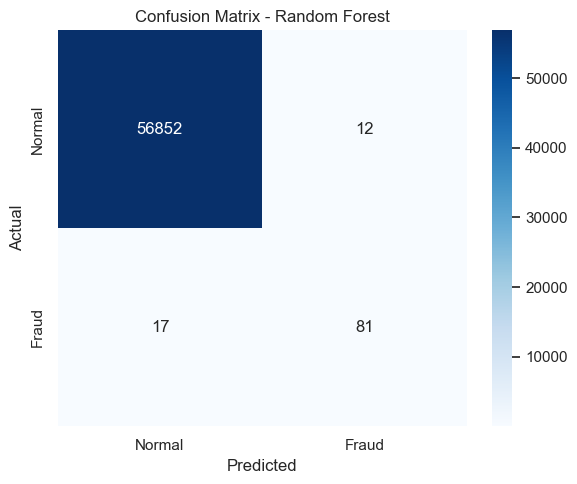

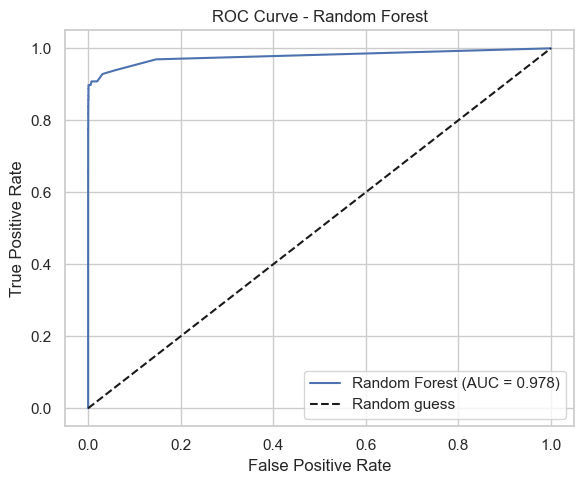

Charts saved as confusion_matrix.png and roc_curve.png


In [16]:
# ===== Cell 8: Visualize results =====

# Re-train the best model (Random Forest) to make charts
best_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
best_model.fit(X_train_balanced, y_train_balanced)
y_pred_best = best_model.predict(X_test)
y_proba_best = best_model.predict_proba(X_test)[:, 1]

# ---- Chart 1: Confusion Matrix ----
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Fraud"],
            yticklabels=["Normal", "Fraud"])
plt.title("Confusion Matrix - Random Forest")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

# ---- Chart 2: ROC Curve ----
fpr, tpr, _ = roc_curve(y_test, y_proba_best)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_proba_best):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.title("ROC Curve - Random Forest")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=150)
plt.show()

print("Charts saved as confusion_matrix.png and roc_curve.png")

Top 10 most important features:
Feature  Importance
    V14    0.189526
    V10    0.112113
     V4    0.109371
    V12    0.091896
    V17    0.088528
     V3    0.064394
    V11    0.048806
    V16    0.045886
     V2    0.037951
     V9    0.025779


C:\Users\96653\AppData\Local\Temp\ipykernel_21904\4246967838.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp.head(10), x="Importance", y="Feature", palette="viridis")


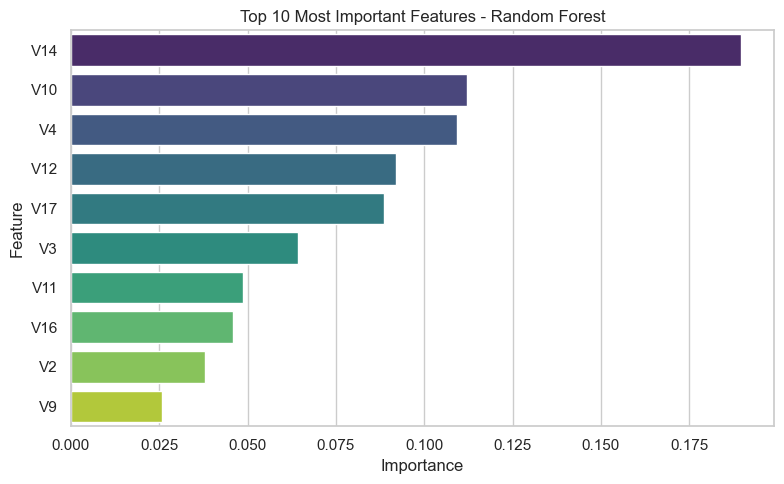


Chart saved as feature_importance.png


In [17]:
# ===== Cell 9: Which features matter most? =====

# Get the importance of each feature from the Random Forest model
feature_names = df.drop("Class", axis=1).columns
importances = best_model.feature_importances_

# Put them in a table and sort from most to least important
feat_imp = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

# Show the top 10 most important features
print("Top 10 most important features:")
print(feat_imp.head(10).to_string(index=False))

# Draw a bar chart of the top 10
plt.figure(figsize=(8, 5))
sns.barplot(data=feat_imp.head(10), x="Importance", y="Feature", palette="viridis")
plt.title("Top 10 Most Important Features - Random Forest")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

print("\nChart saved as feature_importance.png")

In [18]:
# ===== Cell 10: Hyperparameter Tuning (Random Forest) =====
# We try different settings and let the computer find the best combination

from sklearn.model_selection import GridSearchCV

# The list of settings we want to test
# The computer will try every combination of these
param_grid = {
    "n_estimators": [100, 200],        # number of trees
    "max_depth": [10, 20, None],       # how deep each tree can grow (None = unlimited)
    "min_samples_split": [2, 5]        # min samples needed to split a node
}

# Base model to tune
rf = RandomForestClassifier(random_state=42, n_jobs=-1)

# GridSearchCV tries all combinations using cross-validation
# scoring="f1" means we pick the settings that give the best F1-score
# cv=3 means 3-fold cross-validation
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

print("Searching for best settings... this may take a few minutes.")

# Run the search on the balanced training data
grid_search.fit(X_train_balanced, y_train_balanced)

# Show the best settings found
print("\nBest settings found:")
print(grid_search.best_params_)
print("\nBest F1-score during search: {:.4f}".format(grid_search.best_score_))

Searching for best settings... this may take a few minutes.
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best settings found:
{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}

Best F1-score during search: 0.9999


In [19]:
# ===== Cell 11: Test the tuned model on real test data =====

# Build the Random Forest using the BEST settings we just found
tuned_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

# Train it on the balanced training data
tuned_rf.fit(X_train_balanced, y_train_balanced)

# Predict on the REAL (imbalanced) test data
y_pred_tuned = tuned_rf.predict(X_test)
y_proba_tuned = tuned_rf.predict_proba(X_test)[:, 1]

# Measure performance
print("===== TUNED Random Forest (on real test set) =====")
print("Accuracy: {:.4f}".format(accuracy_score(y_test, y_pred_tuned)))
print("Precision: {:.4f}".format(precision_score(y_test, y_pred_tuned)))
print("Recall: {:.4f}".format(recall_score(y_test, y_pred_tuned)))
print("F1-Score: {:.4f}".format(f1_score(y_test, y_pred_tuned)))
print("ROC-AUC: {:.4f}".format(roc_auc_score(y_test, y_proba_tuned)))

print("\n===== ORIGINAL Random Forest (for comparison) =====")
print("Precision: 0.8710 | Recall: 0.8265 | F1-Score: 0.8482 | ROC-AUC: 0.9782")

===== TUNED Random Forest (on real test set) =====
Accuracy: 0.9995
Precision: 0.8876
Recall: 0.8061
F1-Score: 0.8449
ROC-AUC: 0.9754

===== ORIGINAL Random Forest (for comparison) =====
Precision: 0.8710 | Recall: 0.8265 | F1-Score: 0.8482 | ROC-AUC: 0.9782


In [20]:
# ===== Cell 12: Cross-Validation (prove results are stable) =====
# Instead of testing once, we test 5 times on different parts of the data

from sklearn.model_selection import StratifiedKFold, cross_val_score
from imblearn.pipeline import Pipeline as ImbPipeline

# We build a "pipeline" so SMOTE is applied INSIDE each fold correctly
# (SMOTE must only touch the training part of each fold, never the validation part)
pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])

# StratifiedKFold keeps the same fraud ratio in each of the 5 folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Run 5-fold cross-validation, measuring F1-score each time
# We use the FULL scaled data here (the pipeline handles SMOTE per fold)
print("Running 5-fold cross-validation... this may take a few minutes.")
scores = cross_val_score(pipeline, X_scaled, y, cv=cv, scoring="f1", n_jobs=-1)

# Show the results
print("\nF1-score for each of the 5 folds:")
for i, score in enumerate(scores, 1):
    print(f"  Fold {i}: {score:.4f}")

print("\nMean F1-score: {:.4f}".format(scores.mean()))
print("Standard deviation: {:.4f}".format(scores.std()))
print("\nResult: {:.4f} ± {:.4f}".format(scores.mean(), scores.std()))

Running 5-fold cross-validation... this may take a few minutes.

F1-score for each of the 5 folds:
  Fold 1: 0.8387
  Fold 2: 0.9016
  Fold 3: 0.8877
  Fold 4: 0.8342
  Fold 5: 0.8394

Mean F1-score: 0.8603
Standard deviation: 0.0284

Result: 0.8603 ± 0.0284


In [21]:
# ===== Cell 13: Install SHAP =====
!pip install shap -q
print("SHAP installed")

SHAP installed


Calculating SHAP values... please wait.


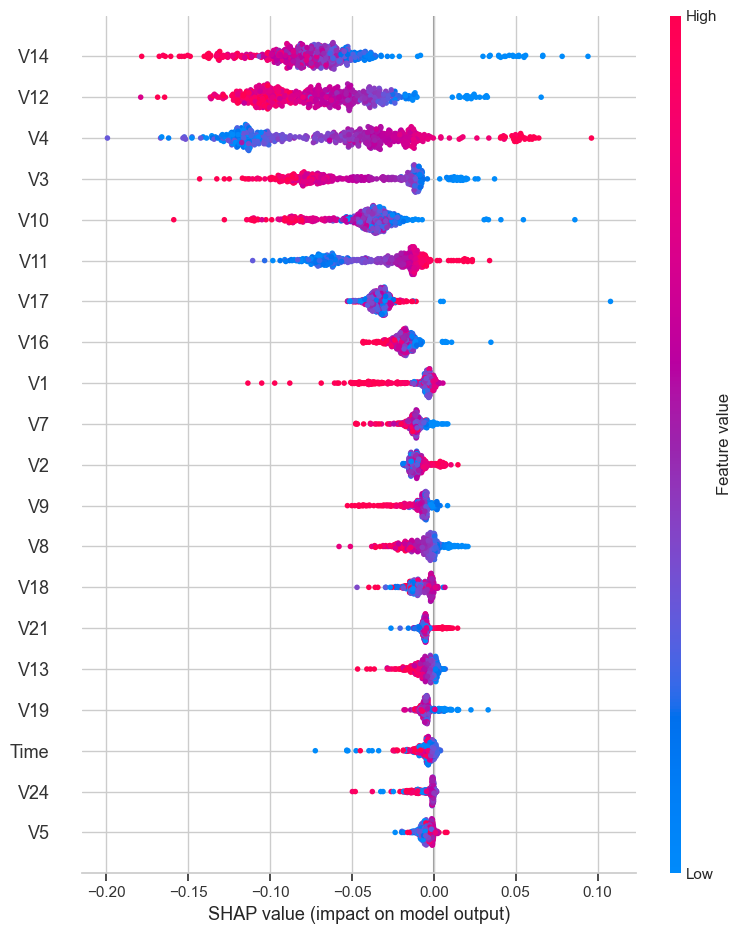


SHAP summary plot saved as shap_summary.png


In [23]:
# ===== Cell 14: SHAP - Explain WHY the model makes decisions =====
# ===== Cell 14: SHAP - Explain WHY the model makes decisions (fixed) =====
import shap

# Re-train the best model
explain_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
explain_model.fit(X_train_balanced, y_train_balanced)

# Take a small sample so SHAP runs fast
X_sample = X_test[:500]
feature_names = df.drop("Class", axis=1).columns

print("Calculating SHAP values... please wait.")

# Use the modern SHAP API (handles the new output format correctly)
explainer = shap.TreeExplainer(explain_model)
explanation = explainer(X_sample)

# For binary classification, select the fraud class (index 1)
# explanation.values shape is (samples, features, classes)
shap_fraud = explanation[:, :, 1]

# ---- SHAP Summary Plot (beeswarm) ----
shap.summary_plot(shap_fraud.values, X_sample,
                  feature_names=feature_names, show=False)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nSHAP summary plot saved as shap_summary.png")

In [24]:
# ===== Cell 15: Save the model for future use =====
import joblib

# Re-train the final model on the balanced data (to be sure it's ready)
final_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
final_model.fit(X_train_balanced, y_train_balanced)

# Save 3 things together in one file:
# 1) the trained model, 2) the scaler, 3) the feature names
bundle = {
    "model": final_model,
    "scaler": scaler,
    "features": list(df.drop("Class", axis=1).columns)
}

# Save to a file
joblib.dump(bundle, "fraud_model.joblib")

print("Model saved as fraud_model.joblib")
print("File contains: model + scaler + feature names")

Model saved as fraud_model.joblib
File contains: model + scaler + feature names


In [25]:
# ===== Cell 16: Load the saved model and predict on NEW data =====
import joblib
import pandas as pd

# Load the saved bundle (model + scaler + features)
bundle = joblib.load("fraud_model.joblib")
model = bundle["model"]
scaler = bundle["scaler"]
features = bundle["features"]

# --- Example: predict on new transactions ---
# In real use, you would load new data from a file:
# new_data = pd.read_csv("new_transactions.csv")
# Here we just take 5 rows from the test set as a demo:
new_data = df.drop("Class", axis=1).iloc[:5]

# IMPORTANT: scale the new data using the SAME scaler
new_scaled = scaler.transform(new_data[features])

# Predict: 0 = normal, 1 = fraud
predictions = model.predict(new_scaled)
probabilities = model.predict_proba(new_scaled)[:, 1]

# Show results
for i, (pred, prob) in enumerate(zip(predictions, probabilities)):
    label = "FRAUD" if pred == 1 else "Normal"
    print(f"Transaction {i+1}: {label}  (fraud probability: {prob:.2%})")

Transaction 1: Normal  (fraud probability: 0.00%)
Transaction 2: Normal  (fraud probability: 0.00%)
Transaction 3: Normal  (fraud probability: 0.00%)
Transaction 4: Normal  (fraud probability: 0.00%)
Transaction 5: Normal  (fraud probability: 0.00%)
